In [1]:
import numpy as np
import pandas as pd

np.random.seed(42)
n = 600

dates = pd.date_range('2026-01-01', '2026-06-30', periods=n).strftime('%Y-%m-%d').tolist()
channels = np.random.choice(
    ['Mobile App', 'Web Store', 'WhatsApp', 'mobile app', ' WEB STORE ', 'whatsapp', '?'],
    size=n,
    p=[0.32, 0.28, 0.22, 0.06, 0.05, 0.04, 0.03]
)
regions = np.random.choice(['Lagos', 'Abuja', 'Port Harcourt', 'Ibadan'], size=n, p=[0.45, 0.25, 0.18, 0.12])

month_num = pd.to_datetime(dates).month
base_rev = np.where(np.char.find(np.char.lower(channels.astype(str)), 'mobile') >= 0, 42000 + month_num * 3500,
           np.where(np.char.find(np.char.lower(channels.astype(str)), 'web') >= 0, 36000, 24000))
revenue_num = (base_rev + np.random.normal(0, 6000, n)).clip(5000, 120000).round(2)
revenue_str = [f"₦{val:,.2f}" for val in revenue_num]

df = pd.DataFrame({
    'order_id': [f"ORD-{1000+i}" for i in range(n)],
    'order_date': dates,
    'channel': channels,
    'region': regions,
    'revenue': revenue_str
})

df.loc[np.random.choice(n, 18, replace=False), 'revenue'] = '?'
df.loc[np.random.choice(n, 12, replace=False), 'revenue'] = np.nan
df.loc[np.random.choice(n, 10, replace=False), 'channel'] = np.nan

df.to_csv('channel_sales_raw.csv', index=False)
df = pd.read_csv('channel_sales_raw.csv')
df.head(15)

,order_id,order_date,channel,region,revenue
0,ORD-1000,2026-01-01,Web Store,Lagos,"₦45,393.14"
1,ORD-1001,2026-01-01,whatsapp,Lagos,"₦23,605.50"
2,ORD-1002,2026-01-01,WhatsApp,Lagos,"₦20,668.80"
3,ORD-1003,2026-01-01,Web Store,Lagos,"₦47,286.94"
4,ORD-1004,2026-01-02,Mobile App,Lagos,"₦36,811.92"
5,ORD-1005,2026-01-02,Mobile App,Abuja,"₦32,307.16"
6,ORD-1006,2026-01-02,Mobile App,Lagos,"₦48,140.09"
7,ORD-1007,2026-01-03,mobile app,Lagos,"₦42,487.67"
8,ORD-1008,2026-01-03,WhatsApp,Abuja,"₦17,872.60"
9,ORD-1009,2026-01-03,WhatsApp,Abuja,"₦28,250.14"


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   order_id    600 non-null    str  
 1   order_date  600 non-null    str  
 2   channel     590 non-null    str  
 3   region      600 non-null    str  
 4   revenue     588 non-null    str  
dtypes: str(5)
memory usage: 50.0 KB


In [3]:
df.shape

(600, 5)

In [4]:

df.isnull().sum()

order_id       0
order_date     0
channel       10
region         0
revenue       12
dtype: int64

In [5]:
#clean data
#replace missing channel


In [6]:
df.isnull().sum()

order_id       0
order_date     0
channel       10
region         0
revenue       12
dtype: int64

In [7]:
most_frequent = df['channel'].value_counts().idxmax()
df['channel'] = df['channel'].fillna(most_frequent)
nullv = df['channel'].isnull().sum()
print(nullv)

0


In [8]:
# 1. Turn '?' into real NaN
df['channel'] = df['channel'].replace('?', np.nan)

# 2. Strip extra spaces and standardize Title Case (' WEB STORE ' -> 'Web Store')
df['channel'] = df['channel'].str.strip().str.title()

# 3. Fill missing values with the mode ('Mobile App')
df['channel'] = df['channel'].fillna(df['channel'].mode()[0])

In [9]:
#clean 
df['revenue'] = (df['revenue'].str.replace("₦",'',regex=False).str.replace(",",'',regex=False))


In [10]:
df['revenue'] = df['revenue'].replace('?', np.nan).astype(float)

In [11]:
#mean
mean_rev = df['revenue'].mean()
df['revenue'] = df['revenue'].fillna(mean_rev)
nullsum = df['revenue'].isnull().sum()
nullsum

np.int64(0)

In [12]:
#date time conversion
df['order_date'] = pd.to_datetime(df['order_date'])

In [13]:

import importlib
import matplotlib.pyplot as plt
importlib.reload(plt)

<module 'matplotlib.pyplot' from 'c:\\Users\\user\\Documents\\Data science\\pyEnv\\Lib\\site-packages\\matplotlib\\pyplot.py'>

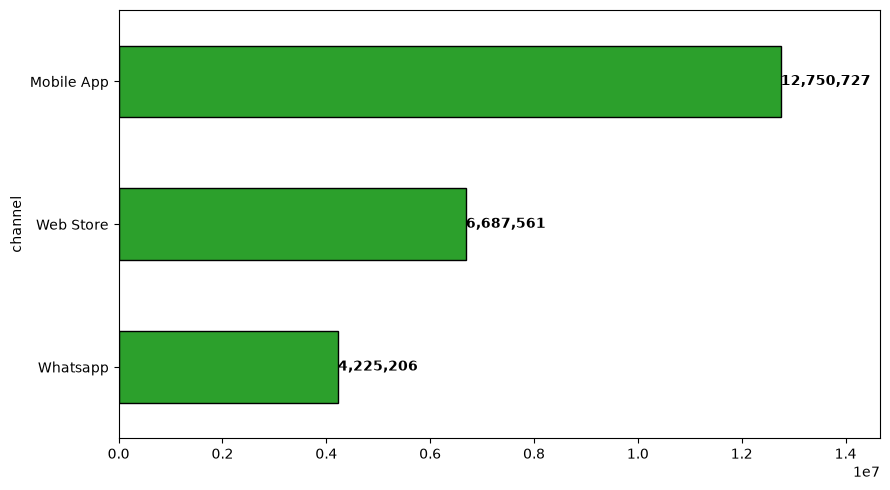

In [17]:
channels_rev = df.groupby('channel')['revenue'].sum().sort_values(ascending=True)
channels_rev.plot(kind='barh',figsize=(9,5), color = '#2ca02c',edgecolor = 'black')
plt.title = ('January -  june channel revenue')
plt.xlabel = 'channel'
plt.ylabel = 'revenue'
plt.xlim(0, channels_rev.max() * 1.15)

for index , value in enumerate(channels_rev):
    plt.annotate(str(f"{value:,.0f}"), xy=(value + 5,index), va = 'center', fontweight = 'bold')
plt.tight_layout()
plt.show()


In [15]:
df['order_date'].dtype
df['month'] = df['order_date'].dt.to_period('M')
df['month']
month_channels_rev = df.groupby(['month','channel'])['revenue'].sum().unstack()

TypeError: 'str' object is not callable

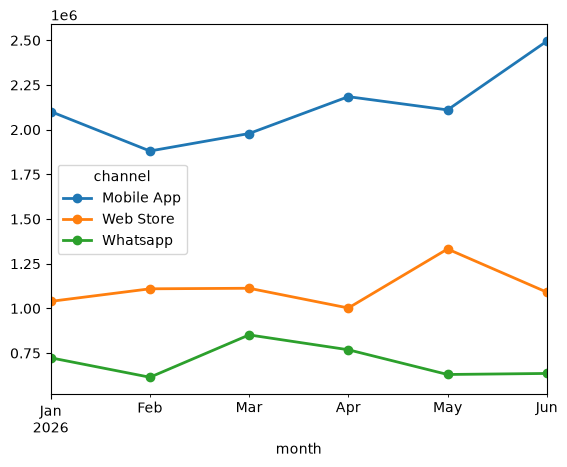

In [16]:
month_channels_rev.plot(kind = 'line',marker = 'o',linewidth = 2.0)
plt.title('monthly channel trend')
plt.xlabel('month')
plt.ylabel('rev')
plt.grid(True,linestyle=":",alpha = 0.5)
plt.legend()
# 3. Display the canvas
plt.tight_layout()
plt.show()